## Importación de librerías

In [3]:
import os
import shutil
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import kagglehub
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

## Sección 1: carga, descarga y preprocesamiento del dataset

In [4]:
# 1. Descarga automática del dataset desde Kaggle
ruta_descarga = kagglehub.dataset_download("drgfreeman/rockpaperscissors")
print("Ruta de descarga:", ruta_descarga)

# Localizar la carpeta que contiene las subcarpetas 'rock', 'paper' y 'scissors'
ruta_origen = ruta_descarga
if "rps-cv-images" in os.listdir(ruta_descarga):
    ruta_origen = os.path.join(ruta_descarga, "rps-cv-images")

# 2. Creación de directorios independientes para train, validation y test
base_dir = "/content/dataset_dividido"
if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

clases = ["rock", "paper", "scissors"]
divisiones = ["train", "validation", "test"]

for div in divisiones:
    for clase in clases:
        os.makedirs(os.path.join(base_dir, div, clase), exist_ok=True)

# 3. División estratificada (70% entrenamiento, 15% validación, 15% prueba)
random.seed(42)
for clase in clases:
    carpeta_clase = os.path.join(ruta_origen, clase)
    imagenes = [f for f in os.listdir(carpeta_clase) if f.endswith(('.png', '.jpg', '.jpeg'))]
    random.shuffle(imagenes)

    total = len(imagenes)
    n_train = int(total * 0.70)
    n_val = int(total * 0.15)

    asignaciones = {
        "train": imagenes[:n_train],
        "validation": imagenes[n_train:n_train + n_val],
        "test": imagenes[n_train + n_val:]
    }

    for div, lista_imgs in asignaciones.items():
        for img in lista_imgs:
            shutil.copy(
                os.path.join(carpeta_clase, img),
                os.path.join(base_dir, div, clase, img)
            )

# 4. Preprocesamiento: redimensionamiento uniforme y normalización [0, 1]
IMG_HEIGHT, IMG_WIDTH = 150, 150
BATCH_SIZE = 32

# El parámetro rescale=1./255 divide cada valor de píxel (0-255) entre 255
generador_datos = ImageDataGenerator(rescale=1./255)

train_generator = generador_datos.flow_from_directory(
    os.path.join(base_dir, "train"),
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

val_generator = generador_datos.flow_from_directory(
    os.path.join(base_dir, "validation"),
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_generator = generador_datos.flow_from_directory(
    os.path.join(base_dir, "test"),
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Using Colab cache for faster access to the 'rockpaperscissors' dataset.
Ruta de descarga: /kaggle/input/rockpaperscissors
Found 1531 images belonging to 3 classes.
Found 326 images belonging to 3 classes.
Found 331 images belonging to 3 classes.


## Sección 2: diseño y construcción de la arquitectura CNN

In [5]:
modelo_cnn = Sequential([
    # Primer bloque convolucional: detección de bordes y contornos básicos
    Conv2D(32, (3, 3), activation="relu", input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    MaxPooling2D(pool_size=(2, 2)),

    # Segundo bloque convolucional: extracción de texturas y formas intermedias
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    # Tercer bloque convolucional: características espaciales complejas de los dedos
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    # Aplanamiento de los mapas de características a un vector unidimensional
    Flatten(),

    # Capa totalmente conectada intermedia con regularización Dropout
    Dense(128, activation="relu"),
    Dropout(0.5),

    # Capa de salida multiclase (3 neuronas con activación Softmax)
    Dense(3, activation="softmax")
])

# Compilación del modelo con Adam, entropía cruzada categórica y precisión
modelo_cnn.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Resumen estructural para documentar parámetros en el reporte
modelo_cnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,739 (18.42 MB)

 Trainable params: 4,828,739 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

## Sección 3: entrenamiento, monitoreo y visualización de curvas de aprendizaje

Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 108s 2s/step - accuracy: 0.6982 - loss: 0.7137 - val_accuracy: 0.8957 - val_loss: 0.3252
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.9131 - loss: 0.2557 - val_accuracy: 0.9325 - val_loss: 0.2149
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.9477 - loss: 0.1444 - val_accuracy: 0.9571 - val_loss: 0.1237
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.9706 - loss: 0.0988 - val_accuracy: 0.9601 - val_loss: 0.1411
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.9732 - loss: 0.0735 - val_accuracy: 0.9479 - val_loss: 0.1713
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.9771 - loss: 0.0607 - val_accuracy: 0.9571 - val_loss: 0.1316
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.9824 - loss: 0.0437 - val_accuracy: 0.9601 - val_loss: 0.1620
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.9843 - loss: 0.0516 - val_accuracy: 0.9663 - val_los

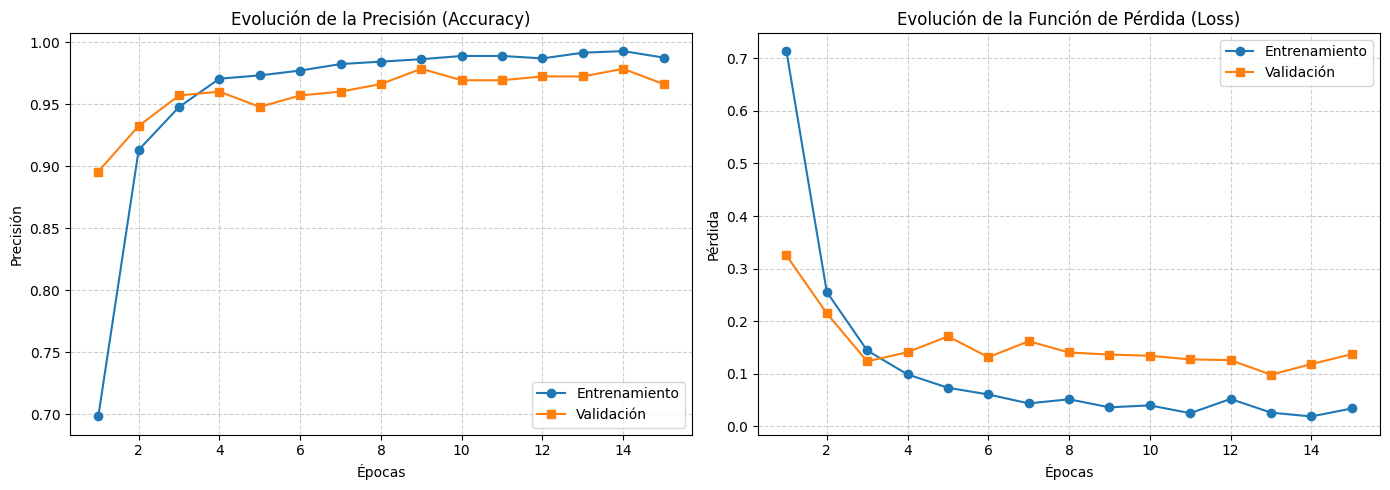

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 537ms/step - accuracy: 0.9728 - loss: 0.1140

Pérdida en conjunto de prueba: 0.1140
Precisión en conjunto de prueba: 97.28%


In [6]:
EPOCAS = 15

# Entrenamiento del modelo supervisando validación en cada época
historial = modelo_cnn.fit(
    train_generator,
    epochs=EPOCAS,
    validation_data=val_generator
)

# Extracción de métricas del historial
acc = historial.history["accuracy"]
val_acc = historial.history["val_accuracy"]
loss = historial.history["loss"]
val_loss = historial.history["val_loss"]
rango_epocas = range(1, EPOCAS + 1)

# Generación de gráficas comparativas con Matplotlib
plt.figure(figsize=(14, 5))

# Gráfica de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(rango_epocas, acc, "o-", label="Entrenamiento")
plt.plot(rango_epocas, val_acc, "s-", label="Validación")
plt.title("Evolución de la Precisión (Accuracy)")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(rango_epocas, loss, "o-", label="Entrenamiento")
plt.plot(rango_epocas, val_loss, "s-", label="Validación")
plt.title("Evolución de la Función de Pérdida (Loss)")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("curvas_aprendizaje.png", dpi=300)
plt.show()

# Evaluación final sobre el conjunto de prueba (Test set)
perdida_test, precision_test = modelo_cnn.evaluate(test_generator)
print(f"\nPérdida en conjunto de prueba: {perdida_test:.4f}")
print(f"Precisión en conjunto de prueba: {precision_test * 100:.2f}%")

## Sección 4: análisis avanzado, matriz de confusión y discusión cítica

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 408ms/step
Reporte de Clasificación por Gesto:

              precision    recall  f1-score   support

       paper     0.9459    0.9722    0.9589       108
        rock     0.9818    0.9818    0.9818       110
    scissors     0.9909    0.9646    0.9776       113

    accuracy                         0.9728       331
   macro avg     0.9729    0.9729    0.9728       331
weighted avg     0.9732    0.9728    0.9729       331



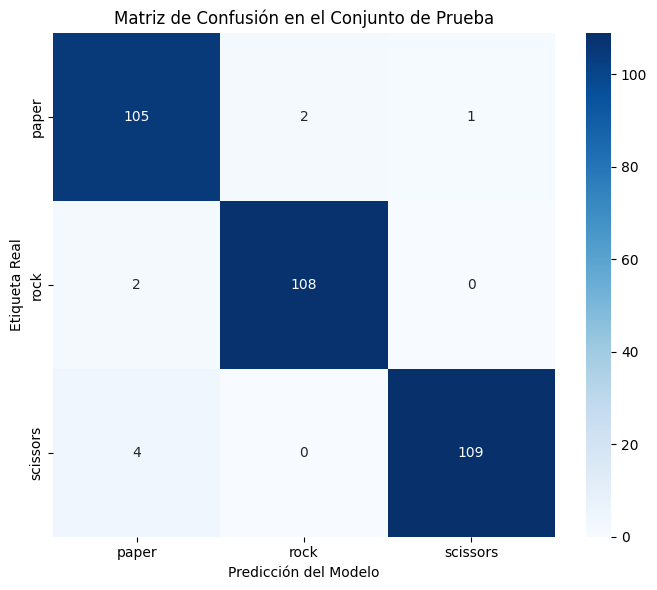

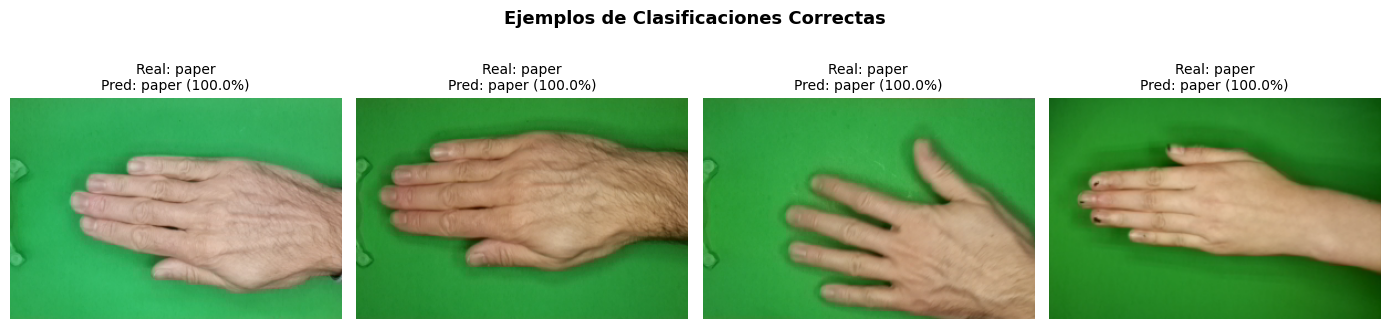

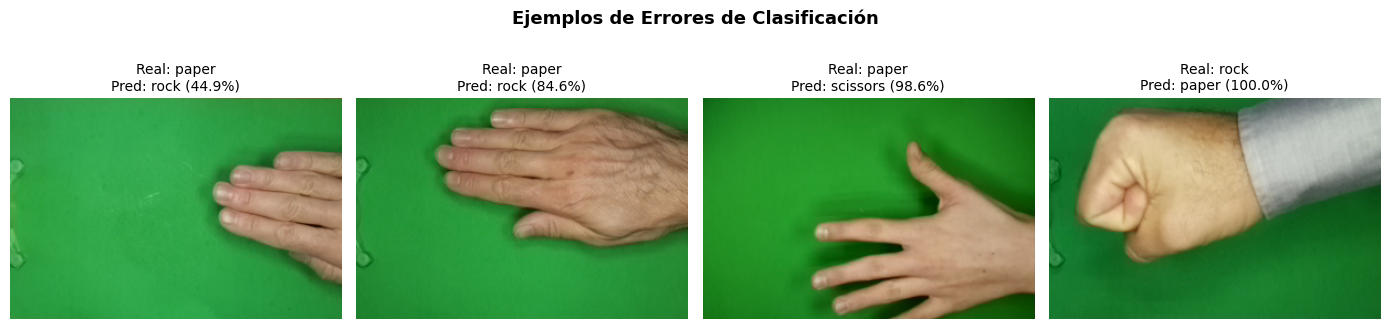

In [7]:
# Reiniciar el generador de prueba para asegurar el orden exacto de las etiquetas
test_generator.reset()
predicciones_prob = modelo_cnn.predict(test_generator)
y_pred = np.argmax(predicciones_prob, axis=1)
y_true = test_generator.classes
nombres_clases = list(test_generator.class_indices.keys())

# 1. Reporte de clasificación detallado (Precision, Recall, F1-score)
print("Reporte de Clasificación por Gesto:\n")
print(classification_report(y_true, y_pred, target_names=nombres_clases, digits=4))

# 2. Matriz de Confusión
matriz = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases
)
plt.title("Matriz de Confusión en el Conjunto de Prueba")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Etiqueta Real")
plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=300)
plt.show()

# 3. Inspección visual de aciertos y errores
rutas_test = test_generator.filepaths
indices_aciertos = np.where(y_pred == y_true)[0]
indices_errores = np.where(y_pred != y_true)[0]

def graficar_ejemplos(indices, titulo_general, nombre_archivo, max_imgs=4):
    seleccion = indices[:max_imgs]
    plt.figure(figsize=(14, 3.8))
    for i, idx in enumerate(seleccion):
        plt.subplot(1, max_imgs, i + 1)
        img = plt.imread(rutas_test[idx])
        plt.imshow(img)
        real_lbl = nombres_clases[y_true[idx]]
        pred_lbl = nombres_clases[y_pred[idx]]
        confianza = np.max(predicciones_prob[idx]) * 100
        plt.title(f"Real: {real_lbl}\nPred: {pred_lbl} ({confianza:.1f}%)", fontsize=10)
        plt.axis("off")
    plt.suptitle(titulo_general, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=300)
    plt.show()

graficar_ejemplos(indices_aciertos, "Ejemplos de Clasificaciones Correctas", "ejemplos_aciertos.png")
if len(indices_errores) > 0:
    graficar_ejemplos(indices_errores, "Ejemplos de Errores de Clasificación", "ejemplos_errores.png")
else:
    print("El modelo no cometió errores en el conjunto de prueba.")